# Ranking de Risco Individual de Attrition

Aplicamos o XGBoost **regularizado** (configuração validada no notebook 06) a todos os colaboradores com `Attrition = No` para estimar a probabilidade individual de saída.

**O que será gerado:**
- Probabilidade de saída (0–100%) por colaborador
- Classificação em faixas: Alto / Médio / Baixo risco
- Visão por profissional: tabela por Departamento × Cargo
- Heatmap de risco médio Department × JobRole
- Perfil comparativo dos colaboradores de alto risco
- Exportação do ranking completo em CSV

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier

SEED = 42
plt.rcParams['figure.dpi'] = 120
sns.set_style('whitegrid')
pd.set_option('display.max_rows', 60)

## 1. Carregamento e treino do modelo final

O XGBoost é retreinado em **todo o dataset histórico** com a mesma configuração regularizada do notebook 06 — `max_depth=3`, `min_child_weight=5`, `reg_alpha=1.0`, `reg_lambda=2.0` — para maximizar o aprendizado antes de pontuar os colaboradores ativos.

In [32]:
general         = pd.read_csv('../data/raw/general_data.csv')
employee_survey = pd.read_csv('../data/raw/employee_survey_data.csv')
manager_survey  = pd.read_csv('../data/raw/manager_survey_data.csv')

df_full = (
    general
    .merge(employee_survey, on='EmployeeID', how='left', validate='one_to_one')
    .merge(manager_survey,  on='EmployeeID', how='left', validate='one_to_one')
)

print(f'Dataset completo: {df_full.shape}')

Dataset completo: (4410, 29)


In [33]:
DROP_COLS = ['EmployeeCount', 'Over18', 'StandardHours']

df_model = df_full.drop(columns=DROP_COLS + ['EmployeeID'])

y_all = (df_model['Attrition'] == 'Yes').astype(int)
X_all = df_model.drop(columns=['Attrition'])

num_cols = X_all.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_all.select_dtypes(include=['object', 'str']).columns.tolist()

print(f'Features: {X_all.shape[1]} | Total: {X_all.shape[0]}')
print(f'Ativos (No): {(y_all == 0).sum()} | Saíram (Yes): {(y_all == 1).sum()}')

Features: 24 | Total: 4410
Ativos (No): 3699 | Saíram (Yes): 711


In [34]:
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
])
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

scale_pos_weight = (y_all == 0).sum() / (y_all == 1).sum()

final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_alpha=1.0,
        reg_lambda=2.0,
        scale_pos_weight=scale_pos_weight,
        random_state=SEED,
        eval_metric='logloss',
        verbosity=0
    ))
])

final_pipeline.fit(X_all, y_all)
print('Modelo final treinado (XGBoost regularizado).')

Modelo final treinado (XGBoost regularizado).


## 2. Scoring dos colaboradores ativos

In [35]:
mask_ativos     = df_full['Attrition'] == 'No'
df_ativos_raw   = df_full[mask_ativos].copy().reset_index(drop=True)
X_ativos        = X_all[mask_ativos].reset_index(drop=True)

print(f'Colaboradores ativos a pontuar: {X_ativos.shape[0]}')

Colaboradores ativos a pontuar: 3699


In [36]:
prob_saida = final_pipeline.predict_proba(X_ativos)[:, 1]

THRESHOLD_ACAO = 0.35

def classify_risk(p):
    if p >= 0.70:   return 'Alto'
    elif p >= 0.35: return 'Medio'
    else:           return 'Baixo'

risk_order = {'Alto': 0, 'Medio': 1, 'Baixo': 2}

df_ranking = df_ativos_raw[[
    'EmployeeID', 'Age', 'Department', 'JobRole', 'JobLevel',
    'MaritalStatus', 'BusinessTravel', 'MonthlyIncome',
    'YearsAtCompany', 'TotalWorkingYears', 'NumCompaniesWorked',
    'JobSatisfaction', 'EnvironmentSatisfaction', 'WorkLifeBalance',
    'JobInvolvement', 'PerformanceRating'
]].copy()

df_ranking['prob_saida']     = prob_saida
df_ranking['prob_saida_pct'] = (prob_saida * 100).round(1)
df_ranking['faixa_risco']    = df_ranking['prob_saida'].apply(classify_risk)
df_ranking['flag_acao']      = (df_ranking['prob_saida'] >= THRESHOLD_ACAO).map(
    {True: 'Conversa recomendada', False: ''}
)

df_ranking = df_ranking.sort_values(
    ['faixa_risco', 'prob_saida'],
    key=lambda s: s.map(risk_order) if s.name == 'faixa_risco' else -s
).reset_index(drop=True)

n_acao   = (df_ranking['prob_saida'] >= THRESHOLD_ACAO).sum()
contagem = df_ranking['faixa_risco'].value_counts()
n_total  = len(df_ranking)

print('Alto risco  :', contagem.get('Alto',  0), 'colaboradores')
print('Medio risco :', contagem.get('Medio', 0), 'colaboradores')
print('Baixo risco :', contagem.get('Baixo', 0), 'colaboradores')
print()
pct_acao = round(n_acao / n_total * 100, 1)
print('Acao recomendada (t >=', THRESHOLD_ACAO, '):', n_acao, 'colaboradores (', pct_acao, '% da base ativa)')


Alto risco  : 88 colaboradores
Medio risco : 1488 colaboradores
Baixo risco : 2123 colaboradores

Acao recomendada (t >= 0.35 ): 1576 colaboradores ( 42.6 % da base ativa)


## 3. Top 50 — maiores probabilidades de saída

In [37]:
top50 = df_ranking.head(50)[[
    'EmployeeID', 'Age', 'Department', 'JobRole', 'JobLevel',
    'MaritalStatus', 'BusinessTravel', 'MonthlyIncome',
    'YearsAtCompany', 'JobSatisfaction', 'faixa_risco', 'prob_saida_pct', 'flag_acao'
]].rename(columns={'prob_saida_pct': 'Prob. Saida (%)'})

display(top50)

,EmployeeID,Age,Department,JobRole,JobLevel,MaritalStatus,BusinessTravel,MonthlyIncome,YearsAtCompany,JobSatisfaction,faixa_risco,Prob. Saida (%),flag_acao
0,44,18,Sales,Research Scientist,1,Single,Travel_Rarely,38120,0,3.0,Alto,84.900002,Conversa recomendada
1,1514,18,Sales,Research Scientist,1,Single,Travel_Rarely,38120,0,3.0,Alto,84.900002,Conversa recomendada
2,2984,18,Sales,Research Scientist,1,Single,Travel_Rarely,38120,0,3.0,Alto,84.900002,Conversa recomendada
3,1314,32,Human Resources,Sales Representative,1,Single,Travel_Rarely,20610,1,1.0,Alto,84.000000,Conversa recomendada
4,2784,32,Human Resources,Sales Representative,1,Single,Travel_Rarely,20610,1,1.0,Alto,84.000000,Conversa recomendada
5,4254,32,Human Resources,Sales Representative,1,Single,Travel_Rarely,20610,1,1.0,Alto,84.000000,Conversa recomendada
6,289,29,Research & Development,Sales Executive,1,Single,Travel_Rarely,106730,1,3.0,Alto,83.099998,Conversa recomendada
7,1759,29,Research & Development,Sales Executive,1,Single,Travel_Rarely,106730,1,3.0,Alto,83.099998,Conversa recomendada
8,3229,29,Research & Development,Sales Executive,1,Single,Travel_Rarely,106730,1,3.0,Alto,83.099998,Conversa recomendada
9,1285,31,Research & Development,Sales Executive,3,Single,Travel_Rarely,42850,1,2.0,Alto,82.699997,Conversa recomendada


## 4. Visão por profissional — Departamento × Cargo

Para cada combinação Departamento + Cargo, listamos todos os colaboradores ativos ordenados por probabilidade de saída. Isso permite ao RH priorizar ações dentro de cada equipe.

In [38]:
cols_view = [
    'EmployeeID', 'Age', 'JobLevel', 'MaritalStatus', 'BusinessTravel',
    'MonthlyIncome', 'YearsAtCompany', 'TotalWorkingYears',
    'JobSatisfaction', 'EnvironmentSatisfaction', 'WorkLifeBalance',
    'faixa_risco', 'prob_saida_pct', 'flag_acao'
]

SEP = '-' * 80

for dept in sorted(df_ranking['Department'].unique()):
    roles = sorted(df_ranking.loc[df_ranking['Department'] == dept, 'JobRole'].unique())
    for role in roles:
        mask   = (df_ranking['Department'] == dept) & (df_ranking['JobRole'] == role)
        subset = (
            df_ranking[mask][cols_view]
            .sort_values('prob_saida_pct', ascending=False)
            .reset_index(drop=True)
        )
        n_acao = (subset['flag_acao'] != '').sum()
        media  = subset['prob_saida_pct'].mean()
        print(SEP)
        print(dept, '->', role)
        print(len(subset), 'colaboradores | Acao recomendada:', n_acao, '| Prob. media:', round(media, 1), '%')
        print(SEP)
        display(subset.rename(columns={'prob_saida_pct': 'Prob. Saida (%)'}))
        print()


--------------------------------------------------------------------------------
Human Resources -> Healthcare Representative
6 colaboradores | Acao recomendada: 3 | Prob. media: 25.0 %
--------------------------------------------------------------------------------


,EmployeeID,Age,JobLevel,MaritalStatus,BusinessTravel,MonthlyIncome,YearsAtCompany,TotalWorkingYears,JobSatisfaction,EnvironmentSatisfaction,WorkLifeBalance,faixa_risco,Prob. Saida (%),flag_acao
0,1006,42,1,Divorced,Travel_Rarely,174650,5,7.0,2.0,2.0,2.0,Medio,35.099998,Conversa recomendada
1,2476,42,1,Divorced,Travel_Rarely,174650,5,7.0,2.0,2.0,2.0,Medio,35.099998,Conversa recomendada
2,3946,42,1,Divorced,Travel_Rarely,174650,5,7.0,2.0,2.0,2.0,Medio,35.099998,Conversa recomendada
3,1244,44,5,Married,Travel_Rarely,47590,4,9.0,4.0,4.0,4.0,Baixo,15.000000,
4,2714,44,5,Married,Travel_Rarely,47590,4,9.0,4.0,4.0,4.0,Baixo,15.000000,
5,4184,44,5,Married,Travel_Rarely,47590,4,9.0,4.0,4.0,4.0,Baixo,15.000000,



--------------------------------------------------------------------------------
Human Resources -> Human Resources
3 colaboradores | Acao recomendada: 3 | Prob. media: 51.6 %
--------------------------------------------------------------------------------


,EmployeeID,Age,JobLevel,MaritalStatus,BusinessTravel,MonthlyIncome,YearsAtCompany,TotalWorkingYears,JobSatisfaction,EnvironmentSatisfaction,WorkLifeBalance,faixa_risco,Prob. Saida (%),flag_acao
0,233,38,1,Single,Travel_Rarely,20140,0,8.0,1.0,3.0,2.0,Medio,51.599998,Conversa recomendada
1,1703,38,1,Single,Travel_Rarely,20140,0,8.0,1.0,3.0,2.0,Medio,51.599998,Conversa recomendada
2,3173,38,1,Single,Travel_Rarely,20140,0,8.0,1.0,3.0,2.0,Medio,51.599998,Conversa recomendada



--------------------------------------------------------------------------------
Human Resources -> Laboratory Technician
21 colaboradores | Acao recomendada: 6 | Prob. media: 30.1 %
--------------------------------------------------------------------------------


,EmployeeID,Age,JobLevel,MaritalStatus,BusinessTravel,MonthlyIncome,YearsAtCompany,TotalWorkingYears,JobSatisfaction,EnvironmentSatisfaction,WorkLifeBalance,faixa_risco,Prob. Saida (%),flag_acao
0,441,35,3,Married,Travel_Rarely,136750,5,5.0,3.0,3.0,3.0,Medio,43.200001,Conversa recomendada
1,1911,35,3,Married,Travel_Rarely,136750,5,5.0,3.0,3.0,3.0,Medio,43.200001,Conversa recomendada
2,3381,35,3,Married,Travel_Rarely,136750,5,5.0,3.0,3.0,3.0,Medio,43.200001,Conversa recomendada
3,552,28,4,Divorced,Travel_Rarely,67810,9,10.0,2.0,4.0,2.0,Medio,35.000000,Conversa recomendada
4,2022,28,4,Divorced,Travel_Rarely,67810,9,10.0,2.0,4.0,2.0,Medio,35.000000,Conversa recomendada
5,3492,28,4,Divorced,Travel_Rarely,67810,9,10.0,2.0,4.0,2.0,Medio,35.000000,Conversa recomendada
6,101,36,2,Single,Non-Travel,24320,1,7.0,4.0,4.0,3.0,Baixo,34.099998,
7,1571,36,2,Single,Non-Travel,24320,1,7.0,4.0,4.0,3.0,Baixo,34.099998,
8,3041,36,2,Single,Non-Travel,24320,1,7.0,4.0,4.0,3.0,Baixo,34.099998,
9,634,44,5,Married,Travel_Rarely,76320,10,10.0,4.0,1.0,3.0,Baixo,33.900002,


... (44 outputs left out)


--------------------------------------------------------------------------------
Sales -> Sales Executive
264 colaboradores | Acao recomendada: 128 | Prob. media: 36.3 %
--------------------------------------------------------------------------------


,EmployeeID,Age,JobLevel,MaritalStatus,BusinessTravel,MonthlyIncome,YearsAtCompany,TotalWorkingYears,JobSatisfaction,EnvironmentSatisfaction,WorkLifeBalance,faixa_risco,Prob. Saida (%),flag_acao
0,53,31,2,Married,Travel_Rarely,132250,2,9.0,1.0,1.0,3.0,Alto,75.099998,Conversa recomendada
1,1523,31,2,Married,Travel_Rarely,132250,2,9.0,1.0,1.0,3.0,Alto,75.099998,Conversa recomendada
2,2993,31,2,Married,Travel_Rarely,132250,2,9.0,1.0,1.0,3.0,Alto,75.099998,Conversa recomendada
3,1062,32,4,Single,Travel_Frequently,43270,0,4.0,4.0,4.0,4.0,Medio,69.599998,Conversa recomendada
4,2532,32,4,Single,Travel_Frequently,43270,0,4.0,4.0,4.0,4.0,Medio,69.599998,Conversa recomendada
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
259,1630,40,1,Married,Travel_Rarely,34820,20,21.0,3.0,3.0,3.0,Baixo,10.700000,
260,3100,40,1,Married,Travel_Rarely,34820,20,21.0,3.0,3.0,3.0,Baixo,10.700000,
261,772,40,1,Divorced,Non-Travel,43420,8,11.0,3.0,3.0,4.0,Baixo,6.100000,
262,2242,40,1,Divorced,Non-Travel,43420,8,11.0,3.0,3.0,4.0,Baixo,6.100000,



--------------------------------------------------------------------------------
Sales -> Sales Representative
51 colaboradores | Acao recomendada: 30 | Prob. media: 35.1 %
--------------------------------------------------------------------------------


,EmployeeID,Age,JobLevel,MaritalStatus,BusinessTravel,MonthlyIncome,YearsAtCompany,TotalWorkingYears,JobSatisfaction,EnvironmentSatisfaction,WorkLifeBalance,faixa_risco,Prob. Saida (%),flag_acao
0,676,28,2,Single,Travel_Rarely,20330,3,5.0,1.0,4.0,2.0,Medio,60.900002,Conversa recomendada
1,2146,28,2,Single,Travel_Rarely,20330,3,5.0,1.0,4.0,2.0,Medio,60.900002,Conversa recomendada
2,3616,28,2,Single,Travel_Rarely,20330,3,5.0,1.0,4.0,2.0,Medio,60.900002,Conversa recomendada
3,1393,31,2,Married,Travel_Rarely,27280,4,7.0,4.0,3.0,3.0,Medio,47.500000,Conversa recomendada
4,2863,31,2,Married,Travel_Rarely,27280,4,7.0,4.0,3.0,3.0,Medio,47.500000,Conversa recomendada
5,4333,31,2,Married,Travel_Rarely,27280,4,7.0,4.0,NaN,3.0,Medio,47.500000,Conversa recomendada
6,1327,34,2,Divorced,Travel_Rarely,50630,1,12.0,2.0,3.0,3.0,Medio,46.200001,Conversa recomendada
7,2797,34,2,Divorced,Travel_Rarely,50630,1,12.0,2.0,3.0,3.0,Medio,46.200001,Conversa recomendada
8,4267,34,2,Divorced,Travel_Rarely,50630,1,12.0,2.0,3.0,3.0,Medio,46.200001,Conversa recomendada
9,660,34,3,Single,Travel_Rarely,74910,3,4.0,1.0,3.0,3.0,Medio,45.400002,Conversa recomendada


## 5. Distribuição geral do risco

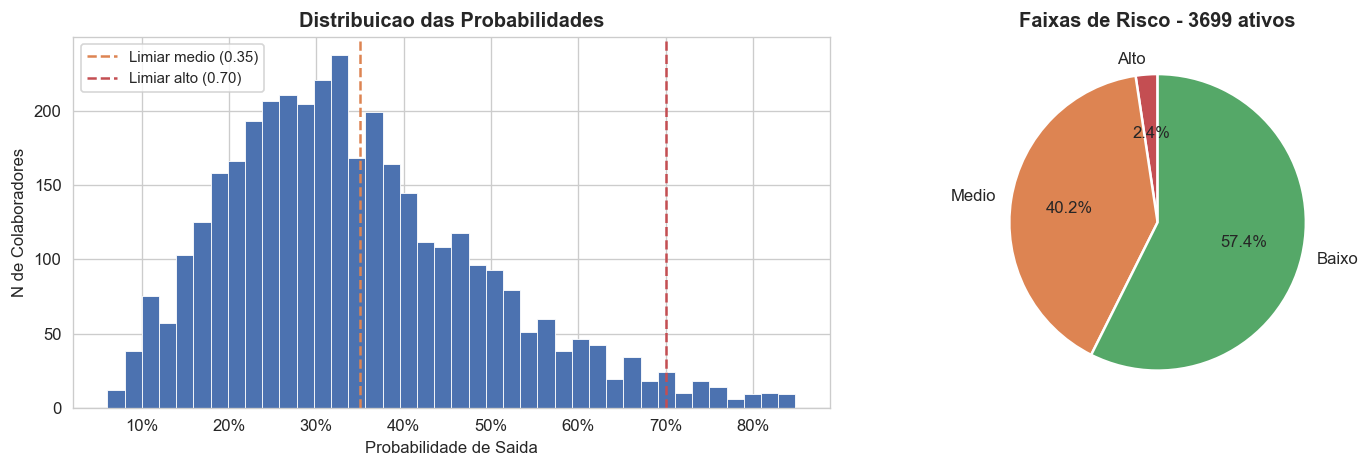

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(prob_saida, bins=40, color='#4C72B0', edgecolor='white', linewidth=0.5)
axes[0].axvline(0.35, color='#DD8452', linestyle='--', lw=1.5, label='Limiar medio (0.35)')
axes[0].axvline(0.70, color='#C44E52', linestyle='--', lw=1.5, label='Limiar alto (0.70)')
axes[0].set_xlabel('Probabilidade de Saida')
axes[0].set_ylabel('N de Colaboradores')
axes[0].set_title('Distribuicao das Probabilidades', fontweight='bold')
axes[0].xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
axes[0].legend(fontsize=9)

faixas = df_ranking['faixa_risco'].value_counts().reindex(['Alto', 'Medio', 'Baixo'])
colors_pizza = ['#C44E52', '#DD8452', '#55A868']
wedges, texts, autotexts = axes[1].pie(
    faixas, labels=faixas.index, autopct='%1.1f%%',
    colors=colors_pizza, startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
for at in autotexts:
    at.set_fontsize(10)
axes[1].set_title('Faixas de Risco - ' + str(len(df_ranking)) + ' ativos', fontweight='bold')

plt.tight_layout()
plt.show()


## 6. Heatmap — Risco médio por Departamento × Cargo

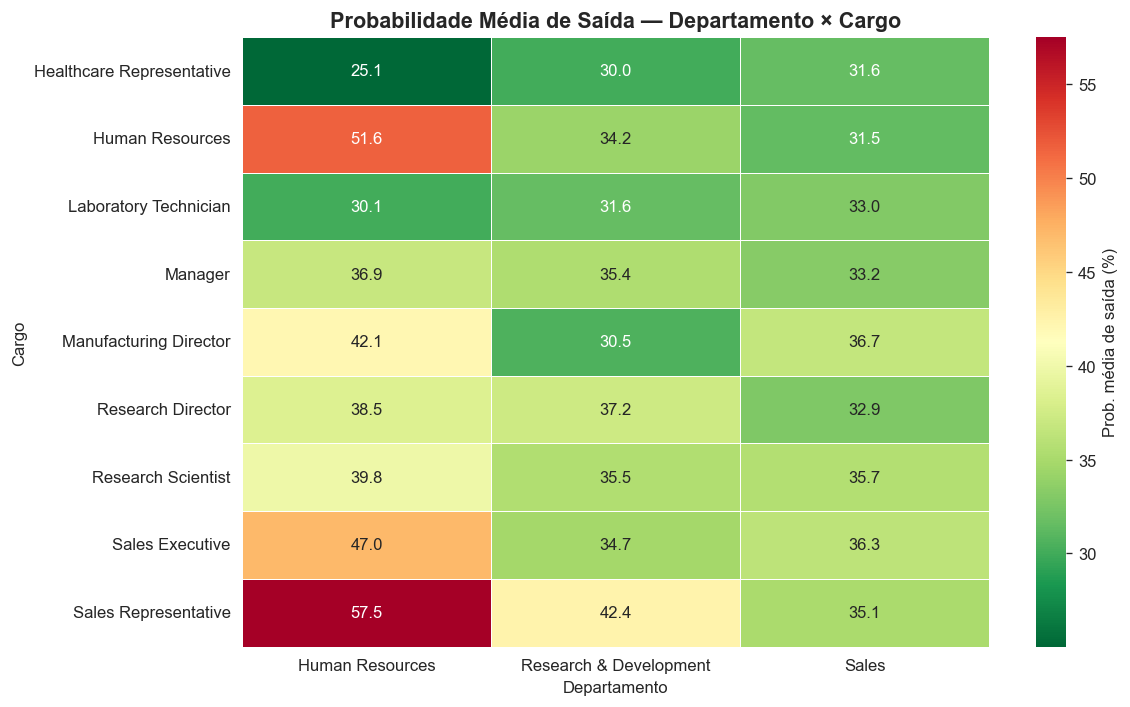

In [40]:
pivot = (
    df_ranking
    .groupby(['Department', 'JobRole'])['prob_saida']
    .mean()
    .unstack('Department')
    .sort_index()
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    pivot * 100,
    annot=True, fmt='.1f', cmap='RdYlGn_r',
    linewidths=0.5, linecolor='white',
    cbar_kws={'label': 'Prob. média de saída (%)'},
    ax=ax
)
ax.set_title('Probabilidade Média de Saída — Departamento × Cargo', fontsize=13, fontweight='bold')
ax.set_xlabel('Departamento')
ax.set_ylabel('Cargo')
plt.tight_layout()
plt.show()

## 7. Risco por segmento

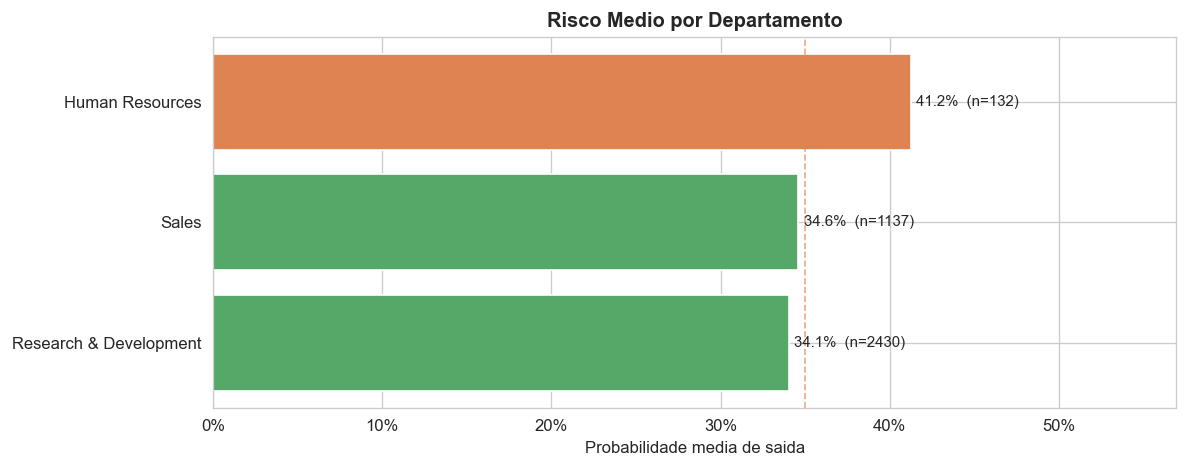

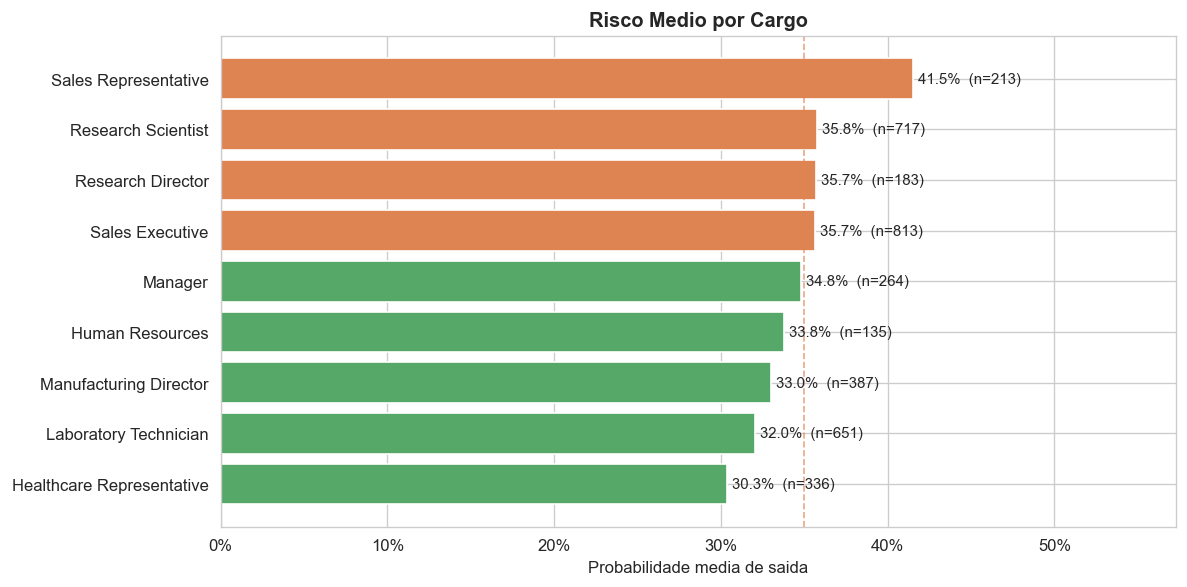

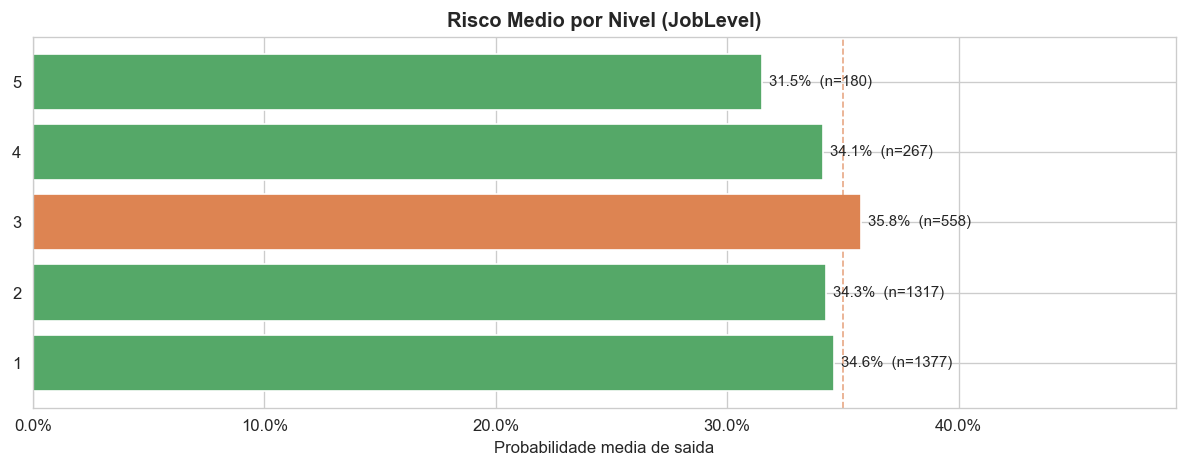

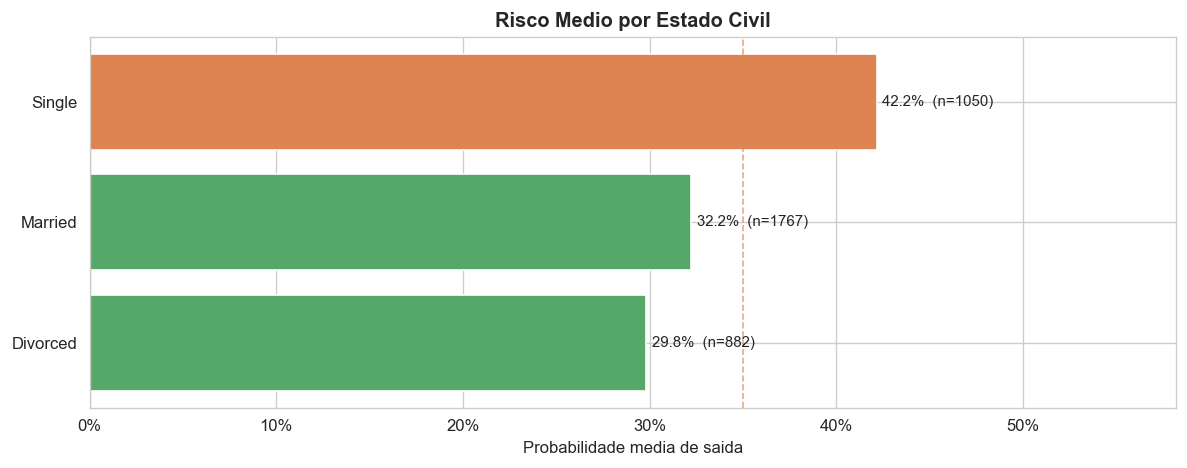

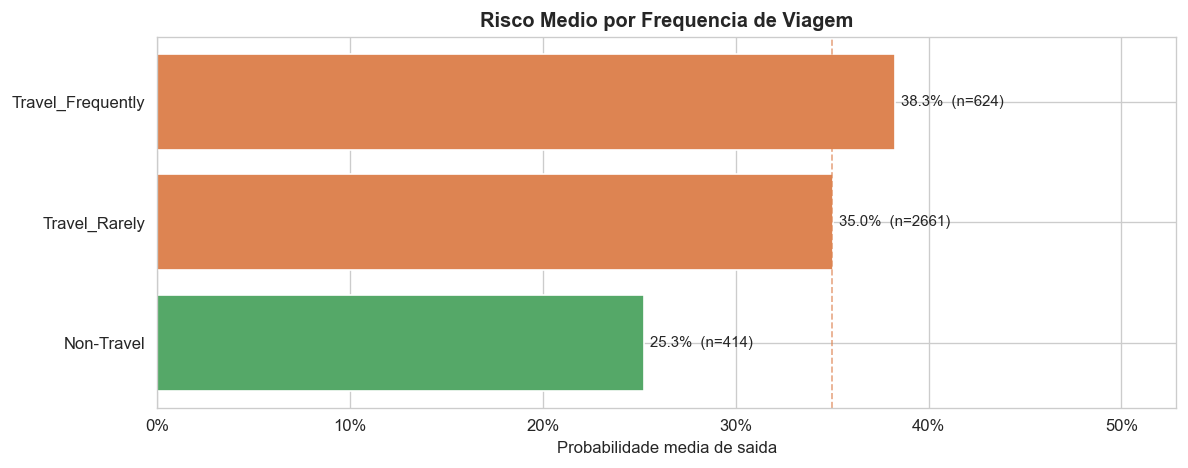

In [41]:
def plot_risk_by_segment(df, col, title, figsize=(10, 4)):
    seg = (
        df.groupby(col)['prob_saida']
        .agg(media='mean', n='count')
        .sort_values('media', ascending=True)
    )
    colors = ['#C44E52' if v >= 0.70 else '#DD8452' if v >= 0.35 else '#55A868'
              for v in seg['media']]

    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.barh(seg.index, seg['media'], color=colors)
    for bar, (idx, row) in zip(bars, seg.iterrows()):
        ax.text(
            bar.get_width() + 0.003, bar.get_y() + bar.get_height() / 2,
            str(round(row['media']*100, 1)) + '%  (n=' + str(int(row['n'])) + ')',
            va='center', fontsize=9
        )
    ax.axvline(0.35, color='#DD8452', linestyle='--', lw=1, alpha=0.7)
    ax.axvline(0.70, color='#C44E52', linestyle='--', lw=1, alpha=0.7)
    ax.set_xlim(0, seg['media'].max() * 1.38)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
    ax.set_xlabel('Probabilidade media de saida')
    ax.set_title(title, fontweight='bold', fontsize=12)
    plt.tight_layout()
    plt.show()

plot_risk_by_segment(df_ranking, 'Department',     'Risco Medio por Departamento')
plot_risk_by_segment(df_ranking, 'JobRole',        'Risco Medio por Cargo', figsize=(10, 5))
plot_risk_by_segment(df_ranking, 'JobLevel',       'Risco Medio por Nivel (JobLevel)')
plot_risk_by_segment(df_ranking, 'MaritalStatus',  'Risco Medio por Estado Civil')
plot_risk_by_segment(df_ranking, 'BusinessTravel', 'Risco Medio por Frequencia de Viagem')


## 8. Perfil dos colaboradores de alto risco

In [42]:
alto_risco   = df_ranking[df_ranking['faixa_risco'] == 'Alto']
todos_ativos = df_ranking

perfil_num = [
    'Age', 'MonthlyIncome', 'YearsAtCompany', 'TotalWorkingYears',
    'NumCompaniesWorked', 'JobSatisfaction', 'EnvironmentSatisfaction',
    'WorkLifeBalance', 'JobInvolvement'
]

comparativo = pd.DataFrame({
    'Alto Risco':   alto_risco[perfil_num].mean(),
    'Todos Ativos': todos_ativos[perfil_num].mean()
}).round(2)
comparativo['Diferenca'] = (comparativo['Alto Risco'] - comparativo['Todos Ativos']).round(2)
comparativo['Delta%'] = ((comparativo['Diferenca'] / comparativo['Todos Ativos']) * 100).round(1).astype(str) + '%'

print('Alto risco:', len(alto_risco), '| Todos ativos:', len(todos_ativos))
display(comparativo)


Alto risco: 88 | Todos ativos: 3699


,Alto Risco,Todos Ativos,Diferenca,Delta%
Age,25.12,37.56,-12.44,-33.1%
MonthlyIncome,75974.32,65672.60,10301.72,15.7%
YearsAtCompany,1.65,7.37,-5.72,-77.6%
TotalWorkingYears,2.82,11.86,-9.04,-76.2%
NumCompaniesWorked,1.76,2.65,-0.89,-33.6%
JobSatisfaction,2.33,2.78,-0.45,-16.2%
EnvironmentSatisfaction,2.42,2.77,-0.35,-12.6%
WorkLifeBalance,2.82,2.78,0.04,1.4%
JobInvolvement,2.52,2.73,-0.21,-7.7%


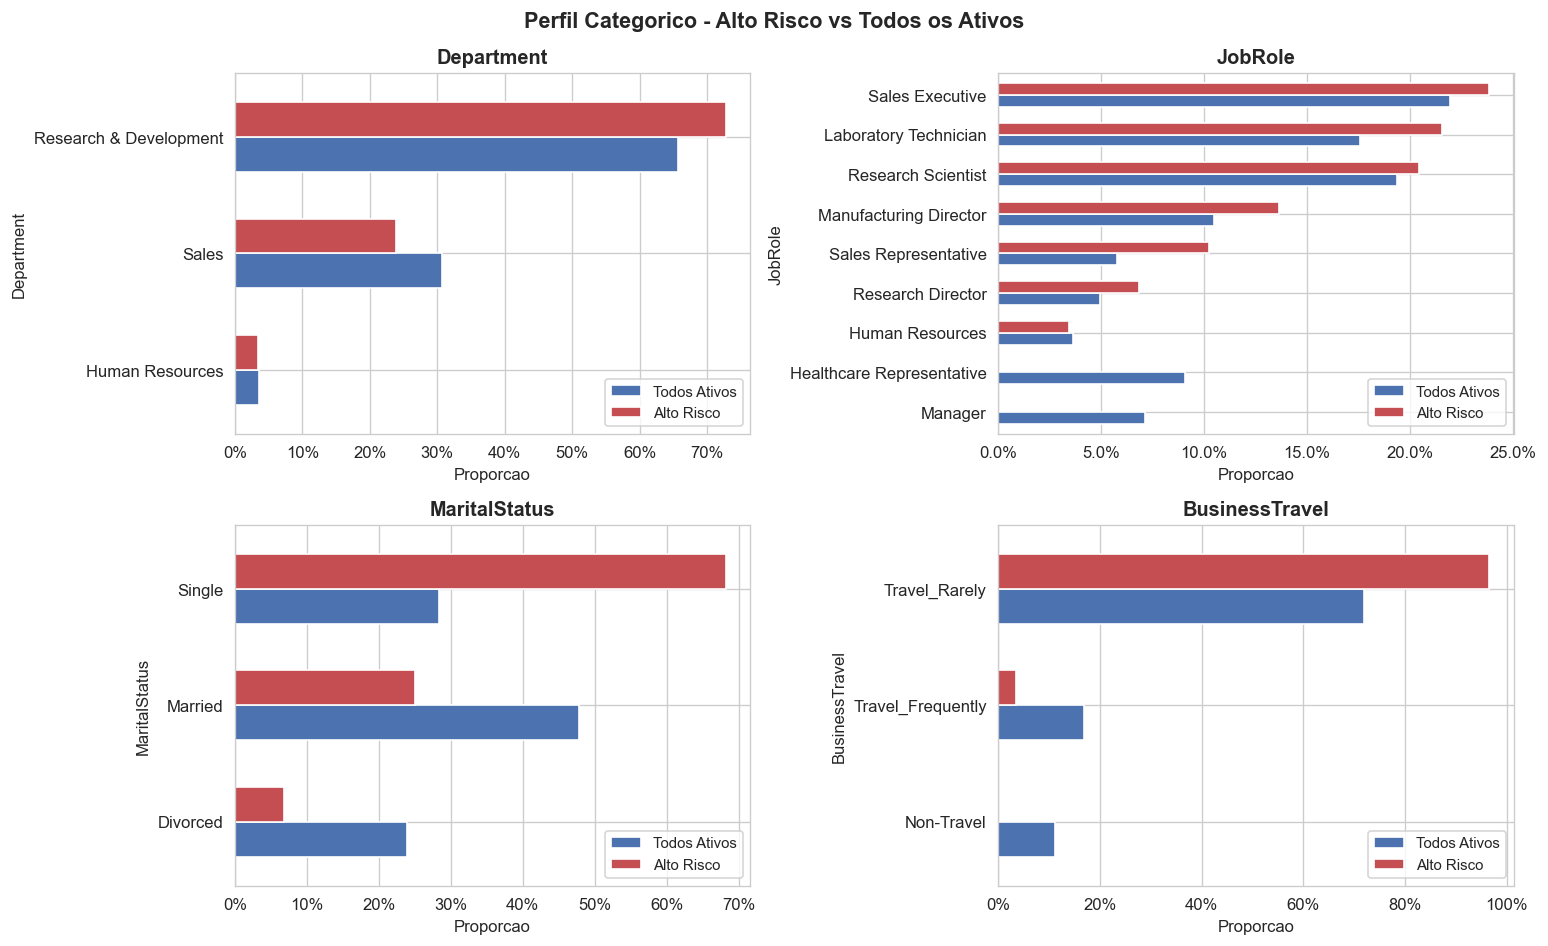

In [43]:
cat_perfil = ['Department', 'JobRole', 'MaritalStatus', 'BusinessTravel']

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes = axes.flatten()

for ax, col in zip(axes, cat_perfil):
    total_pct = todos_ativos[col].value_counts(normalize=True).rename('Todos Ativos')
    alto_pct  = alto_risco[col].value_counts(normalize=True).rename('Alto Risco')
    comp = pd.concat([total_pct, alto_pct], axis=1).fillna(0).sort_values('Alto Risco', ascending=True)

    comp.plot(kind='barh', ax=ax, color=['#4C72B0', '#C44E52'], width=0.6)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
    ax.set_title(col, fontweight='bold')
    ax.set_xlabel('Proporcao')
    ax.legend(fontsize=9)

fig.suptitle('Perfil Categorico - Alto Risco vs Todos os Ativos', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 9. Exportação

In [44]:
df_export = df_ranking[[
    'EmployeeID', 'Age', 'Department', 'JobRole', 'JobLevel',
    'MaritalStatus', 'BusinessTravel', 'MonthlyIncome',
    'YearsAtCompany', 'TotalWorkingYears',
    'JobSatisfaction', 'EnvironmentSatisfaction', 'WorkLifeBalance',
    'prob_saida_pct', 'faixa_risco', 'flag_acao'
]].rename(columns={
    'prob_saida_pct': 'Probabilidade_Saida_Pct',
    'faixa_risco':    'Faixa_Risco',
    'flag_acao':      'Acao_RH'
})

output_path = '../data/raw/attrition_risk_ranking.csv'
df_export.to_csv(output_path, index=False)

print(f'Exportado: {output_path}')
print(f'Total: {len(df_export)} colaboradores ativos')
print(f'Com acao recomendada: {(df_export["Acao_RH"] != "").sum()}')
display(df_export.head(10))

Exportado: ../data/raw/attrition_risk_ranking.csv
Total: 3699 colaboradores ativos
Com acao recomendada: 1576


,EmployeeID,Age,Department,JobRole,JobLevel,MaritalStatus,BusinessTravel,MonthlyIncome,YearsAtCompany,TotalWorkingYears,JobSatisfaction,EnvironmentSatisfaction,WorkLifeBalance,Probabilidade_Saida_Pct,Faixa_Risco,Acao_RH
0,44,18,Sales,Research Scientist,1,Single,Travel_Rarely,38120,0,0.0,3.0,4.0,3.0,84.900002,Alto,Conversa recomendada
1,1514,18,Sales,Research Scientist,1,Single,Travel_Rarely,38120,0,0.0,3.0,4.0,3.0,84.900002,Alto,Conversa recomendada
2,2984,18,Sales,Research Scientist,1,Single,Travel_Rarely,38120,0,0.0,3.0,4.0,3.0,84.900002,Alto,Conversa recomendada
3,1314,32,Human Resources,Sales Representative,1,Single,Travel_Rarely,20610,1,1.0,1.0,4.0,3.0,84.000000,Alto,Conversa recomendada
4,2784,32,Human Resources,Sales Representative,1,Single,Travel_Rarely,20610,1,1.0,1.0,4.0,3.0,84.000000,Alto,Conversa recomendada
5,4254,32,Human Resources,Sales Representative,1,Single,Travel_Rarely,20610,1,1.0,1.0,4.0,3.0,84.000000,Alto,Conversa recomendada
6,289,29,Research & Development,Sales Executive,1,Single,Travel_Rarely,106730,1,1.0,3.0,3.0,3.0,83.099998,Alto,Conversa recomendada
7,1759,29,Research & Development,Sales Executive,1,Single,Travel_Rarely,106730,1,1.0,3.0,3.0,3.0,83.099998,Alto,Conversa recomendada
8,3229,29,Research & Development,Sales Executive,1,Single,Travel_Rarely,106730,1,1.0,3.0,3.0,3.0,83.099998,Alto,Conversa recomendada
9,1285,31,Research & Development,Sales Executive,3,Single,Travel_Rarely,42850,1,1.0,2.0,3.0,3.0,82.699997,Alto,Conversa recomendada
